# Tugas PCD & Visi Komputer — Pengenalan Gestur Tangan dan Deteksi Wajah dengan MediaPipe

| | |
|---|---|
| **Nama** | Nadhif Rif'at Rasendriya |
| **NIM** | 235150201111074 |
| **Mata kuliah** | CIF61339 — Pengolahan Citra Digital dan Visi Komputer |
| **Tugas** | MediaPipe (Hand Landmarker + Face Detector), pengerjaan individu |
| **Batas pengumpulan** | Sabtu, 14 November 2026, pukul 20.00 WIB |
| **Berkas** | `MediaPipe_235150201111074_NadhifRifatRasendriya.ipynb` |

**Ruang lingkup.** Hanya model pra-latih MediaPipe yang dipakai. Tidak ada pelatihan model, tidak ada foto orang lain, dan tidak ada pengenalan identitas (hanya *face detection*).

**Alur notebook**

0. Setup lingkungan dan model
1. **Tugas 1** — gestur tangan: data HaGRID → landmarks → aturan PALM/FIST → evaluasi → analisis
2. **Tugas 2** — deteksi wajah: data FaceSynthetics → bounding box → jumlah wajah → analisis
3. **Visualisasi, analisis, atribusi** — ringkasan, referensi, dan lisensi

Main GitHub Repository: https://github.com/nadhif-royal/mediapipe-hand-gesture-face-detection

References GitHub Repository: https://github.com/hukenovs/hagrid

## Kaitan dengan materi kuliah

- **Pipeline dua tahap pada MediaPipe** (materi *Pose Estimation*): tahap 1 mendeteksi objek (kotak pembatas), tahap 2 memperkirakan *landmark* di dalam kotak itu. *Hand Landmarker* memakai pola yang sama dan menghasilkan **21 landmark tangan** (x, y, z), sedangkan *Pose* menghasilkan 33 landmark tubuh.
- **Face Detector MediaPipe** adalah detektor berbasis CNN yang hanya mengembalikan **kotak wajah + skor keyakinan**. Ini berbeda dari Haar Cascade (fitur terang-gelap + integral image + AdaBoost, materi *HaarCascade vs FaceNet*), yang lebih sensitif terhadap pose, rotasi, dan pencahayaan.
- **Keluaran sesuai materi Pose Estimation:** keypoints (x, y) dinormalisasi lalu *didenormalisasi* ke piksel citra asli (dilakukan di Step 1.3), ada *confidence score* (kolom "Skor tangan"), dan koordinat z hanya kedalaman relatif sehingga tidak dipakai pada aturan 2D ini. Mode `IMAGE` dipakai karena inputnya citra tunggal, jadi fase *tracking*/*smoothing* (EMA) untuk video tidak berlaku.
- **Deteksi ≠ pengenalan** (materi *HaarCascade vs FaceNet*): tugas ini hanya menentukan *lokasi* wajah, bukan *siapa* orangnya (FaceNet/embedding tidak dipakai).

---
# Step 0 — Setup Lingkungan dan Model

## 0.1 Instal pustaka

`mediapipe` untuk model pra-latih, `opencv-python-headless` untuk membaca dan menggambar pada citra.
Jika Colab meminta *restart runtime* setelah instalasi, jalankan ulang dari sel ini.

In [1]:
!pip install -q mediapipe opencv-python-headless

## 0.2 Impor pustaka dan identitas

In [2]:
import os, re, glob, zipfile, urllib.request
import numpy as np
import cv2
import pandas as pd
import matplotlib.pyplot as plt
import mediapipe as mp
from mediapipe.tasks import python as mp_python
from mediapipe.tasks.python import vision
from IPython.display import display, Markdown

NAMA = "Nadhif Rif'at Rasendriya"
NIM = "235150201111074"

print("Nama        :", NAMA)
print("NIM         :", NIM)
print("MediaPipe   :", mp.__version__)
print("OpenCV      :", cv2.__version__)

Nama        : Nadhif Rif'at Rasendriya
NIM         : 235150201111074
MediaPipe   : 1.2.3
OpenCV      : 4.14.0


## 0.3 Unduh model pra-latih resmi MediaPipe

- **Hand Landmarker** → `hand_landmarker.task`
- **Face Detector (BlazeFace short-range)** → `blaze_face_short_range.tflite`

Keduanya diunduh dari penyimpanan model resmi MediaPipe (Google). Dokumentasi:
[Hand Landmarker](https://ai.google.dev/edge/mediapipe/solutions/vision/hand_landmarker/python) ·
[Face Detector](https://ai.google.dev/edge/mediapipe/solutions/vision/face_detector/python).

In [3]:
MODEL_DIR = "models"
os.makedirs(MODEL_DIR, exist_ok=True)

HAND_MODEL_URL = ("https://storage.googleapis.com/mediapipe-models/hand_landmarker/"
                  "hand_landmarker/float16/1/hand_landmarker.task")
FACE_MODEL_URL = ("https://storage.googleapis.com/mediapipe-models/face_detector/"
                  "blaze_face_short_range/float16/1/blaze_face_short_range.tflite")

HAND_MODEL = os.path.join(MODEL_DIR, "hand_landmarker.task")
FACE_MODEL = os.path.join(MODEL_DIR, "blaze_face_short_range.tflite")

def download(url, dest):
    """Unduh file jika belum ada."""
    if os.path.exists(dest) and os.path.getsize(dest) > 0:
        print(f"[skip] {dest} sudah ada ({os.path.getsize(dest)/1e6:.1f} MB)")
        return dest
    os.makedirs(os.path.dirname(dest) or ".", exist_ok=True)
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0 (Colab; PCD-MediaPipe-assignment)"})
    with urllib.request.urlopen(req, timeout=180) as r, open(dest, "wb") as f:
        f.write(r.read())
    print(f"[ok]   {dest} ({os.path.getsize(dest)/1e6:.1f} MB)")
    return dest

download(HAND_MODEL_URL, HAND_MODEL)
download(FACE_MODEL_URL, FACE_MODEL)

[ok]   models/hand_landmarker.task (7.8 MB)
[ok]   models/blaze_face_short_range.tflite (0.2 MB)


'models/blaze_face_short_range.tflite'

## 0.4 Fungsi bantu (baca citra)

Citra dibaca dengan OpenCV (BGR) lalu diubah ke RGB, karena MediaPipe dan Matplotlib memakai RGB.
Orientasi EXIF diterapkan otomatis oleh `cv2.imread`.

In [4]:
IMG_EXT = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

def load_rgb(path):
    bgr = cv2.imread(path, cv2.IMREAD_COLOR)
    if bgr is None:
        raise FileNotFoundError(f"Gagal membaca citra: {path}")
    return cv2.cvtColor(bgr, cv2.COLOR_BGR2RGB)

def to_mp_image(rgb):
    return mp.Image(image_format=mp.ImageFormat.SRGB, data=np.ascontiguousarray(rgb))

def ip(p):
    """Titik (x, y) -> tuple int Python (aman untuk OpenCV)."""
    return int(round(float(p[0]))), int(round(float(p[1])))

---
# Tugas 1 — Pengenalan Gestur Tangan (HaGRID)

Target: membedakan **PALM** (telapak terbuka) dan **FIST** (kepalan) dari 10 gambar HaGRID (5 palm + 5 fist) memakai **MediaPipe Hand Landmarker** dan **aturan sederhana tanpa pelatihan model**.

## Step 1.1 — 10 gambar HaGRID

Gambar disimpan ke `data/hagrid/palm/` dan `data/hagrid/fist/`. **Folder menjadi label acuan (ground truth).**

In [5]:
HAGRID_DIR = "data/hagrid"
for c in ("palm", "fist"):
    os.makedirs(os.path.join(HAGRID_DIR, c), exist_ok=True)

def upload_to_class(class_name):
    """Upload gambar lewat dialog Colab dan simpan ke folder kelasnya."""
    from google.colab import files
    print(f"Pilih 5 gambar kelas '{class_name.upper()}' ...")
    uploaded = files.upload()
    for fname, content in uploaded.items():
        with open(os.path.join(HAGRID_DIR, class_name, os.path.basename(fname)), "wb") as f:
            f.write(content)
    print(f"{len(uploaded)} file disimpan ke {HAGRID_DIR}/{class_name}/")

In [6]:
# # Upload 5 gambar PALM
# upload_to_class("palm")

In [7]:
# # Upload 5 gambar FIST
# upload_to_class("fist")

In [8]:
# Instal remotezip untuk mengambil 5 sampel pertama langsung dari ZIP resmi tanpa download penuh
!pip install -q remotezip

import os, re, urllib.request
from remotezip import RemoteZip

HAGRID_DIR = "data/hagrid"
for c in ("palm", "fist"):
    os.makedirs(os.path.join(HAGRID_DIR, c), exist_ok=True)

# 1. Baca README.md resmi HaGRID untuk mencari link ZIP dataset
readme_url = "https://raw.githubusercontent.com/hukenovs/hagrid/master/README.md"
readme_text = urllib.request.urlopen(readme_url, timeout=30).read().decode("utf-8")
zip_urls = re.findall(r'https?://[^\s"\'<>()]+\.zip', readme_text)

print(f"Ditemukan {len(zip_urls)} link .zip di README resmi HaGRID.")

# Cadangan link resmi SberCloud HaGRID jika format README berubah
FALLBACK_URLS = {
    "subsample": [
        "https://rndml-team-cv.obs.ru-moscow-1.hc.sbercloud.ru/datasets/hagrid/subsamples/subsample.zip",
        "https://rndml-team-cv.obs.ru-moscow-1.hc.sbercloud.ru/datasets/hagrid/hagrid-sample-30k-384p.zip",
    ],
    "palm": [
        "https://rndml-team-cv.obs.ru-moscow-1.hc.sbercloud.ru/datasets/hagrid_v2/hagridv2_512/palm.zip",
        "https://rndml-team-cv.obs.ru-moscow-1.hc.sbercloud.ru/datasets/hagrid/test/palm.zip",
        "https://rndml-team-cv.obs.ru-moscow-1.hc.sbercloud.ru/datasets/hagrid/train_val_palm.zip",
    ],
    "fist": [
        "https://rndml-team-cv.obs.ru-moscow-1.hc.sbercloud.ru/datasets/hagrid_v2/hagridv2_512/fist.zip",
        "https://rndml-team-cv.obs.ru-moscow-1.hc.sbercloud.ru/datasets/hagrid/test/fist.zip",
        "https://rndml-team-cv.obs.ru-moscow-1.hc.sbercloud.ru/datasets/hagrid/train_val_fist.zip",
    ],
}

# Kategorikan link dari README + Fallback
palm_candidates = [u for u in zip_urls if "palm" in u.lower()] + FALLBACK_URLS["palm"]
fist_candidates = [u for u in zip_urls if "fist" in u.lower()] + FALLBACK_URLS["fist"]
sub_candidates  = [u for u in zip_urls if "sub" in u.lower() or "sample" in u.lower()] + FALLBACK_URLS["subsample"]

IMG_EXT = (".jpg", ".jpeg", ".png")

def fetch_first_5_from_class_zip(cls_name, url_list):
    """Ambil 5 gambar pertama (urut abjad) dari ZIP khusus satu kelas."""
    out_dir = os.path.join(HAGRID_DIR, cls_name)
    for url in url_list:
        try:
            print(f"[{cls_name.upper()}] Mencoba membaca daftar file dari: {url} ...")
            with RemoteZip(url) as z:
                imgs = sorted(f for f in z.namelist()
                              if f.lower().endswith(IMG_EXT) and not os.path.basename(f).startswith("."))
                if len(imgs) >= 5:
                    for member in imgs[:5]:
                        fname = os.path.basename(member)
                        with open(os.path.join(out_dir, fname), "wb") as f_out:
                            f_out.write(z.read(member))
                        print(f"  -> Tersimpan: {out_dir}/{fname}")
                    return True
        except Exception as e:
            print(f"  [lewat] Gagal akses {url}: {e}")
    return False

def fetch_first_5_from_subsample(url_list):
    """Ambil 5 gambar pertama palm & fist dari ZIP gabungan subsample."""
    for url in url_list:
        try:
            print(f"[SUBSAMPLE] Mencoba membaca daftar file dari: {url} ...")
            with RemoteZip(url) as z:
                all_files = z.namelist()
                for cls_name in ("palm", "fist"):
                    out_dir = os.path.join(HAGRID_DIR, cls_name)
                    imgs = sorted(f for f in all_files
                                  if f.lower().endswith(IMG_EXT)
                                  and f"/{cls_name}/" in ("/" + f.lower().replace("\\", "/"))
                                  and not os.path.basename(f).startswith("."))
                    if len(imgs) < 5:
                        raise RuntimeError(f"File kelas {cls_name} kurang dari 5 di ZIP ini.")
                    for member in imgs[:5]:
                        fname = os.path.basename(member)
                        with open(os.path.join(out_dir, fname), "wb") as f_out:
                            f_out.write(z.read(member))
                        print(f"  -> Tersimpan: {out_dir}/{fname}")
                return True
        except Exception as e:
            print(f"  [lewat] Gagal akses {url}: {e}")
    return False

ok_palm = fetch_first_5_from_class_zip("palm", palm_candidates)
ok_fist = fetch_first_5_from_class_zip("fist", fist_candidates)

if not (ok_palm and ok_fist):
    print("\nMencoba mengambil dari paket Subsample gabungan...")
    fetch_first_5_from_subsample(sub_candidates)

print("\nSelesai! Jumlah file saat ini:")
for c in ("palm", "fist"):
    files_c = sorted(os.listdir(os.path.join(HAGRID_DIR, c)))
    print(f" - {c.upper()} ({len(files_c)} file): {files_c}")

Ditemukan 36 link .zip di README resmi HaGRID.
[PALM] Mencoba membaca daftar file dari: https://rndml-team-cv.obs.ru-moscow-1.hc.sbercloud.ru/datasets/hagrid/hagrid_dataset_new_554800/hagrid_dataset/palm.zip ...
  -> Tersimpan: data/hagrid/palm/00008ff0-b235-4007-8466-a98e2c5b8ccb.jpg
  -> Tersimpan: data/hagrid/palm/00040338-47ea-4a95-87d0-7cf1f57174ce.jpg
  -> Tersimpan: data/hagrid/palm/00066533-90c0-4f03-87f6-adfeb47aa80b.jpg
  -> Tersimpan: data/hagrid/palm/00080ad4-3dbf-4939-b349-d33c558229ce.jpg
  -> Tersimpan: data/hagrid/palm/00088b36-4ac7-4331-8197-698df71c66bb.jpg
[FIST] Mencoba membaca daftar file dari: https://rndml-team-cv.obs.ru-moscow-1.hc.sbercloud.ru/datasets/hagrid/hagrid_dataset_new_554800/hagrid_dataset/fist.zip ...
  -> Tersimpan: data/hagrid/fist/0003d89b-0472-4ad4-80f5-96e9969afff5.jpg
  -> Tersimpan: data/hagrid/fist/00046dcf-b4b2-4f63-8a8d-039a1a17b8c8.jpg
  -> Tersimpan: data/hagrid/fist/00086aac-e142-4c40-a7fe-5ad5e60f580b.jpg
  -> Tersimpan: data/hagrid/fis

Simpan 10 gambar ke laptop saya

In [9]:
import shutil
from google.colab import files

shutil.make_archive("10_gambar_hagrid", "zip", "data/hagrid")
files.download("10_gambar_hagrid.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Step 1.2 — Verifikasi dan kunci daftar 10 gambar

Pemilihan dibuat **deterministik**: jika ada lebih dari 5 gambar per kelas, diambil 5 pertama menurut urutan nama file. Dengan begitu, gambar tidak dipilih berdasarkan hasil akurasi.

In [10]:
def list_images(folder):
    return sorted(p for p in glob.glob(os.path.join(folder, "*"))
                  if p.lower().endswith(IMG_EXT))

GESTURE_ITEMS = []   # (path, label_folder)
for cls in ("palm", "fist"):
    imgs = list_images(os.path.join(HAGRID_DIR, cls))
    if len(imgs) < 5:
        raise RuntimeError(f"Kelas '{cls}' hanya punya {len(imgs)} gambar, butuh 5. Upload ulang.")
    if len(imgs) > 5:
        print(f"[info] kelas '{cls}' berisi {len(imgs)} gambar; dipakai 5 pertama (urut nama).")
    GESTURE_ITEMS += [(p, cls) for p in imgs[:5]]

print(f"Total gambar gestur: {len(GESTURE_ITEMS)} (5 palm + 5 fist)\n")
for i, (p, c) in enumerate(GESTURE_ITEMS, 1):
    img = load_rgb(p)
    print(f"{i:2d}. [{c.upper():4s}] {os.path.basename(p)}  ukuran={img.shape[1]}x{img.shape[0]}")

Total gambar gestur: 10 (5 palm + 5 fist)

 1. [PALM] 00008ff0-b235-4007-8466-a98e2c5b8ccb.jpg  ukuran=1425x1920
 2. [PALM] 00040338-47ea-4a95-87d0-7cf1f57174ce.jpg  ukuran=1440x1920
 3. [PALM] 00066533-90c0-4f03-87f6-adfeb47aa80b.jpg  ukuran=1920x1440
 4. [PALM] 00080ad4-3dbf-4939-b349-d33c558229ce.jpg  ukuran=800x600
 5. [PALM] 00088b36-4ac7-4331-8197-698df71c66bb.jpg  ukuran=1440x1920
 6. [FIST] 0003d89b-0472-4ad4-80f5-96e9969afff5.jpg  ukuran=960x1280
 7. [FIST] 00046dcf-b4b2-4f63-8a8d-039a1a17b8c8.jpg  ukuran=960x1280
 8. [FIST] 00086aac-e142-4c40-a7fe-5ad5e60f580b.jpg  ukuran=1440x1920
 9. [FIST] 000b9676-731b-4001-a658-d46b9389fc0e.jpg  ukuran=1920x1440
10. [FIST] 000ed71d-3661-4aa9-b38b-104d2f3013b4.jpg  ukuran=1440x1920


## Step 1.3 — Jalankan MediaPipe Hand Landmarker

Model mendeteksi tangan lalu memperkirakan **21 landmark**. Skema penomoran:

- `0` = pergelangan tangan (*wrist*)
- tiap jari punya 4 titik dari pangkal ke ujung: **MCP → PIP → DIP → TIP**
  (telunjuk 5–8, tengah 9–12, manis 13–16, kelingking 17–20; ibu jari 1–4)

Koordinat keluaran MediaPipe ternormalisasi (0–1), maka dikonversi ke **piksel** agar jarak tidak terdistorsi oleh rasio aspek citra.
Jika tidak ada tangan terdeteksi, hasilnya `None` (nantinya diberi label **NOT DETECTED**).

In [11]:
hand_options = vision.HandLandmarkerOptions(
    base_options=mp_python.BaseOptions(model_asset_path=HAND_MODEL),
    running_mode=vision.RunningMode.IMAGE,
    num_hands=1,
    min_hand_detection_confidence=0.5,
    min_hand_presence_confidence=0.5,
    min_tracking_confidence=0.5,
)
hand_landmarker = vision.HandLandmarker.create_from_options(hand_options)

def detect_hand_landmarks(rgb):
    """Kembalikan (landmarks, skor). landmarks: array (21, 2) piksel (denormalisasi), None bila tidak terdeteksi."""
    result = hand_landmarker.detect(to_mp_image(rgb))
    if not result.hand_landmarks:
        return None, None
    h, w = rgb.shape[:2]
    pts = np.array([[lm.x * w, lm.y * h] for lm in result.hand_landmarks[0]], dtype=np.float64)
    try:
        score = float(result.handedness[0][0].score)      # confidence score model
    except Exception:
        score = None
    return pts, score

print("Hand Landmarker siap.")

Hand Landmarker siap.


## Step 1.4 — Fungsi menggambar landmark dan garis penghubung

Garis penghubung didefinisikan manual (tidak bergantung pada modul `mp.solutions` yang bisa berbeda antarversi).

In [12]:
HAND_CONNECTIONS = [
    (0, 1), (1, 2), (2, 3), (3, 4),            # ibu jari
    (0, 5), (5, 6), (6, 7), (7, 8),            # telunjuk
    (5, 9), (9, 10), (10, 11), (11, 12),       # jari tengah
    (9, 13), (13, 14), (14, 15), (15, 16),     # jari manis
    (13, 17), (17, 18), (18, 19), (19, 20),    # kelingking
    (0, 17),                                   # tepi telapak
]

def draw_hand(rgb, pts):
    """Gambar garis (hijau) dan titik (merah) landmark pada salinan citra."""
    out = rgb.copy()
    s = max(1, int(round(max(out.shape[:2]) / 400)))   # skala ketebalan
    for a, b in HAND_CONNECTIONS:
        cv2.line(out, ip(pts[a]), ip(pts[b]), (0, 255, 0), s)
    for p in pts:
        cv2.circle(out, ip(p), s * 2, (255, 0, 0), -1)
    return out

## Step 1.5 — Aturan sederhana PALM vs FIST (tanpa pelatihan model)

**Ide.** Pada jari yang **lurus**, ujung jari (TIP) berada *lebih jauh* dari pergelangan tangan dibanding sendi tengah (PIP). Pada jari yang **menekuk**, ujung jari ditarik ke telapak sehingga jaraknya ke pergelangan tangan menjadi sama atau lebih pendek dari jarak PIP.

Untuk tiap jari (telunjuk, tengah, manis, kelingking):

$$\text{rasio} = \frac{\lVert \text{TIP} - \text{WRIST} \rVert}{\lVert \text{PIP} - \text{WRIST} \rVert}$$

- Jari dianggap **lurus** bila `rasio > EXT_RATIO` (**1.15**).
- Gestur adalah **PALM** bila minimal **3 dari 4 jari** lurus, selain itu **FIST**.
- Tidak ada tangan terdeteksi → **NOT DETECTED**.

**Penjelasan pilihan:**
- Memakai *rasio jarak* membuat aturan tidak terpengaruh ukuran tangan atau jarak ke kamera, dan tidak bergantung pada orientasi (rotasi) tangan di citra.
- Ibu jari **tidak dipakai** dalam keputusan karena geraknya menyamping dan uji jarak-ke-pergelangan tidak andal untuk ibu jari.
- Ambang 1.15 dan syarat minimal 3 jari ditetapkan **sebelum** melihat hasil pengujian (bukan disetel agar akurasi 10/10). Nilainya berada di antara kondisi jari lurus (rasio jauh di atas 1) dan menekuk (rasio sekitar atau di bawah 1).

In [13]:
FINGERS = {            # nama: (indeks PIP, indeks TIP)
    "index":  (6, 8),
    "middle": (10, 12),
    "ring":   (14, 16),
    "pinky":  (18, 20),
}
EXT_RATIO = 1.15       # jari lurus bila TIP/PIP (jarak ke wrist) > nilai ini
MIN_EXTENDED_FOR_PALM = 3

def finger_ratios(pts):
    wrist = pts[0]
    dist = lambda i: float(np.linalg.norm(pts[i] - wrist))
    return {name: dist(tip) / (dist(pip) + 1e-9) for name, (pip, tip) in FINGERS.items()}

def classify_gesture(pts):
    """Kembalikan (label, info). label in {'PALM','FIST','NOT DETECTED'}."""
    if pts is None:
        return "NOT DETECTED", {"n_extended": None}
    ratios = finger_ratios(pts)
    n_ext = sum(r > EXT_RATIO for r in ratios.values())
    label = "PALM" if n_ext >= MIN_EXTENDED_FOR_PALM else "FIST"
    return label, {"n_extended": n_ext, **ratios}

print(f"Aturan aktif: jari lurus jika rasio > {EXT_RATIO}; PALM jika >= {MIN_EXTENDED_FOR_PALM} dari 4 jari lurus.")

Aturan aktif: jari lurus jika rasio > 1.15; PALM jika >= 3 dari 4 jari lurus.


## Step 1.6 — Jalankan pipeline pada 10 gambar

Untuk setiap gambar: deteksi landmark → gambar landmark → klasifikasi → bandingkan dengan label folder.
Prediksi dihitung **benar** hanya jika label prediksi sama dengan label folder (`NOT DETECTED` dihitung salah).

In [14]:
gesture_rows, gesture_vis = [], []

for idx, (path, truth) in enumerate(GESTURE_ITEMS, 1):
    rgb = load_rgb(path)
    pts, hscore = detect_hand_landmarks(rgb)
    pred, info = classify_gesture(pts)
    correct = (pred.lower() == truth)
    vis = draw_hand(rgb, pts) if pts is not None else rgb

    gesture_rows.append({
        "No": idx,
        "File": os.path.basename(path),
        "Label folder": truth.upper(),
        "Prediksi": pred,
        "Skor tangan": None if hscore is None else round(hscore, 2),
        "Jari lurus (dari 4)": info["n_extended"],
        "rasio index":  None if pts is None else round(info["index"], 2),
        "rasio middle": None if pts is None else round(info["middle"], 2),
        "rasio ring":   None if pts is None else round(info["ring"], 2),
        "rasio pinky":  None if pts is None else round(info["pinky"], 2),
        "Benar": correct,
    })
    gesture_vis.append((vis, truth, pred, correct))

df_gesture = pd.DataFrame(gesture_rows)
df_gesture["Jari lurus (dari 4)"] = df_gesture["Jari lurus (dari 4)"].astype("Int64")   # tampil sebagai bilangan bulat
display(df_gesture)

,No,File,Label folder,Prediksi,Skor tangan,Jari lurus (dari 4),rasio index,rasio middle,rasio ring,rasio pinky,Benar
0,1,00008ff0-b235-4007-8466-a98e2c5b8ccb.jpg,PALM,PALM,0.97,4,1.32,1.33,1.36,1.34,True
1,2,00040338-47ea-4a95-87d0-7cf1f57174ce.jpg,PALM,PALM,0.98,4,1.31,1.32,1.30,1.30,True
2,3,00066533-90c0-4f03-87f6-adfeb47aa80b.jpg,PALM,PALM,0.94,4,1.31,1.32,1.32,1.30,True
3,4,00080ad4-3dbf-4939-b349-d33c558229ce.jpg,PALM,PALM,0.86,4,1.31,1.32,1.31,1.29,True
4,5,00088b36-4ac7-4331-8197-698df71c66bb.jpg,PALM,PALM,0.94,4,1.30,1.31,1.31,1.29,True
5,6,0003d89b-0472-4ad4-80f5-96e9969afff5.jpg,FIST,FIST,1.00,0,0.58,0.50,0.47,0.56,True
6,7,00046dcf-b4b2-4f63-8a8d-039a1a17b8c8.jpg,FIST,FIST,1.00,0,0.67,0.62,0.61,0.68,True
7,8,00086aac-e142-4c40-a7fe-5ad5e60f580b.jpg,FIST,FIST,0.99,2,1.30,1.14,1.11,1.17,True
8,9,000b9676-731b-4001-a658-d46b9389fc0e.jpg,FIST,FIST,0.99,0,0.68,0.67,0.68,0.74,True
9,10,000ed71d-3661-4aa9-b38b-104d2f3013b4.jpg,FIST,FIST,0.99,0,0.74,0.69,0.65,0.71,True


## Step 1.7 — Tampilkan 10 hasil berlabel (5 per kelas)

Judul hijau = prediksi benar, merah = salah. Baris atas: label folder PALM; baris bawah: label folder FIST.

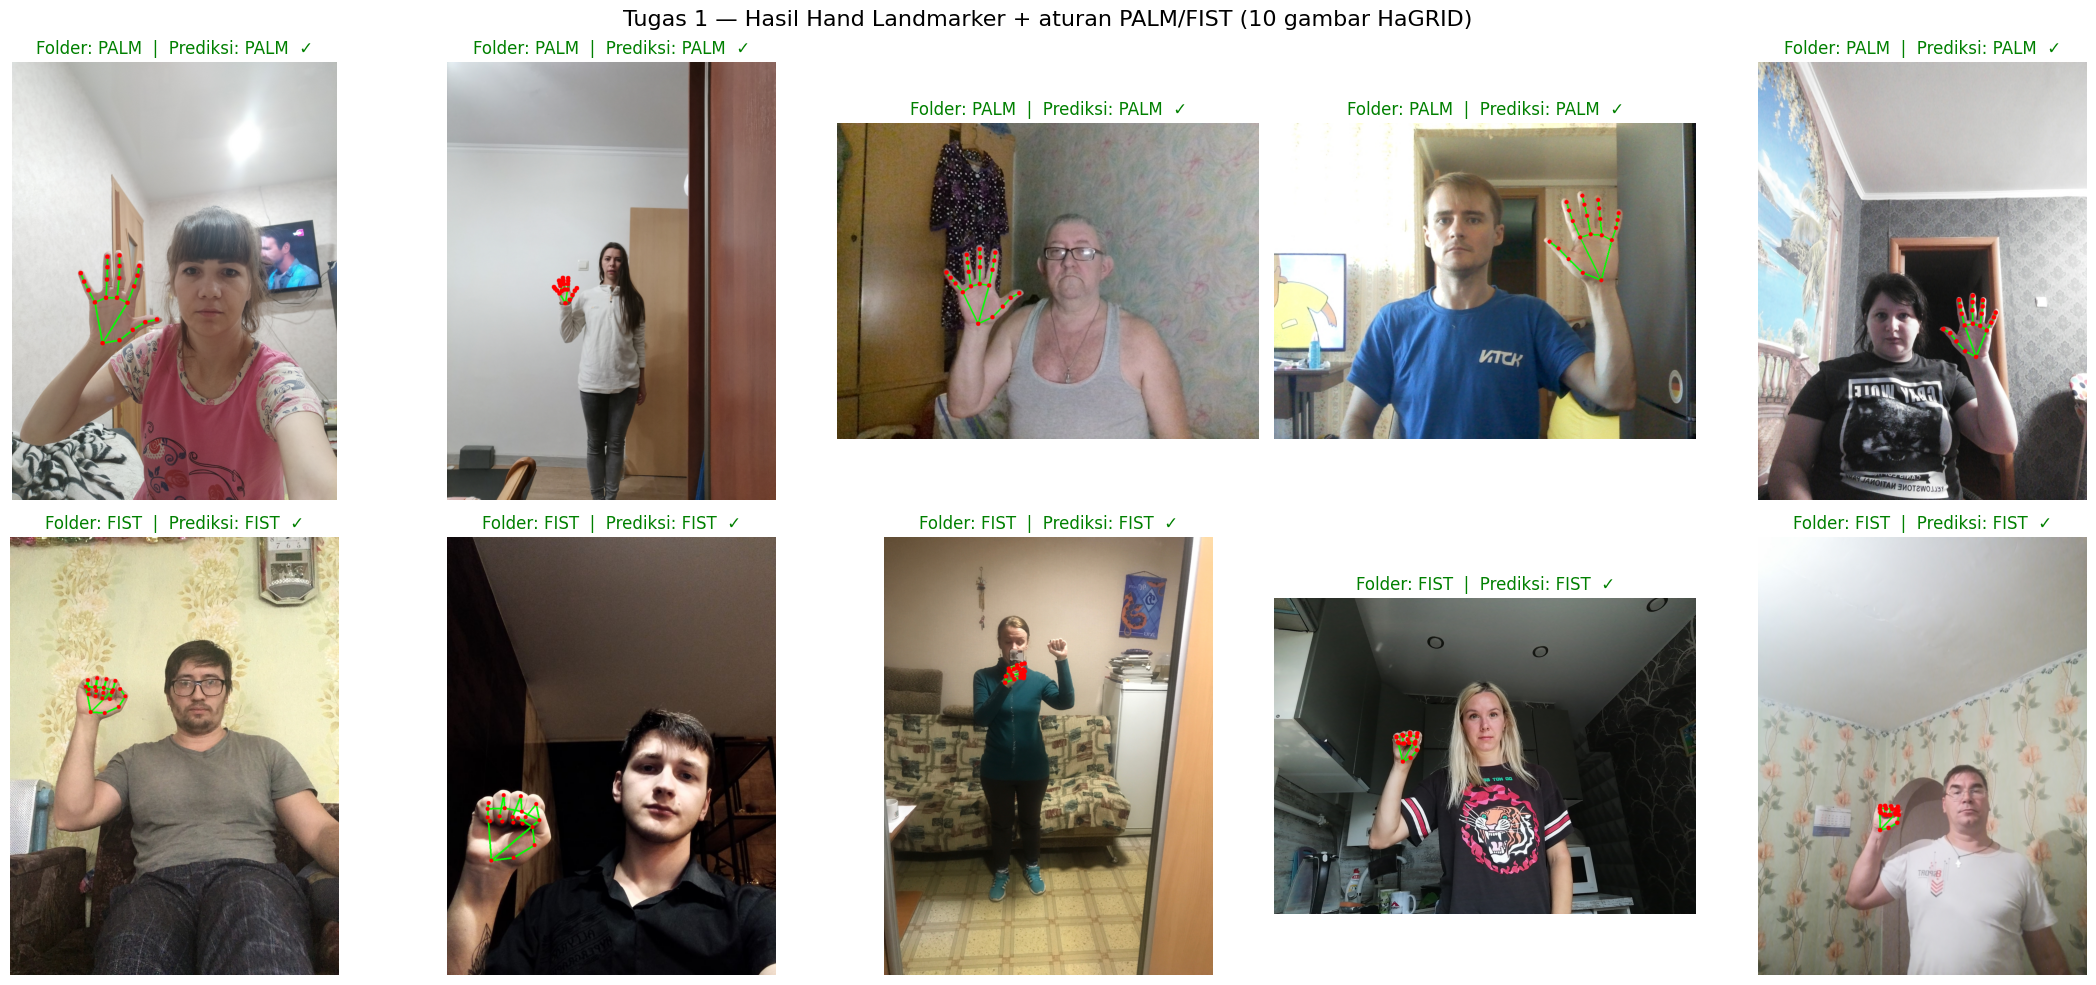

In [15]:
fig, axes = plt.subplots(2, 5, figsize=(22, 10))
for ax, (vis, truth, pred, ok) in zip(axes.ravel(), gesture_vis):
    ax.imshow(vis)
    ax.set_title(f"Folder: {truth.upper()}  |  Prediksi: {pred}  {'✓' if ok else '✗'}",
                 fontsize=12, color=("green" if ok else "red"))
    ax.axis("off")
fig.suptitle("Tugas 1 — Hasil Hand Landmarker + aturan PALM/FIST (10 gambar HaGRID)", fontsize=16)
plt.tight_layout()
plt.show()

## Step 1.8 — Jumlah prediksi benar

In [16]:
n_correct = int(df_gesture["Benar"].sum())
n_total = len(df_gesture)
n_not_det = int((df_gesture["Prediksi"] == "NOT DETECTED").sum())

print(f"Prediksi benar : {n_correct} dari {n_total}  (akurasi {n_correct / n_total:.0%})")
for cls in ("PALM", "FIST"):
    sub = df_gesture[df_gesture["Label folder"] == cls]
    print(f"  - {cls}: {int(sub['Benar'].sum())} dari {len(sub)} benar")
print(f"Tidak terdeteksi (NOT DETECTED): {n_not_det}")

# Confusion matrix (baris = label folder, kolom = prediksi)
display(pd.crosstab(df_gesture["Label folder"], df_gesture["Prediksi"]))

Prediksi benar : 10 dari 10  (akurasi 100%)
  - PALM: 5 dari 5 benar
  - FIST: 5 dari 5 benar
Tidak terdeteksi (NOT DETECTED): 0


Prediksi,FIST,PALM
Label folder,,
FIST,5,0
PALM,0,5


## Step 1.9 — Analisis kesalahan dan keterbatasan

In [17]:
def build_gesture_analysis(df, n_correct, n_total):
    wrong = df[~df["Benar"]]
    s1 = (f"Dari {n_total} gambar HaGRID, {n_correct} diprediksi benar (akurasi {n_correct / n_total:.0%}) "
          f"dengan aturan jumlah jari lurus (rasio TIP/PIP > {EXT_RATIO}, PALM jika >= {MIN_EXTENDED_FOR_PALM} dari 4 jari).")
    if wrong.empty:
        s2 = "Semua gambar benar, tetapi hanya 10 sampel sehingga belum membuktikan aturan ini tahan terhadap variasi."
        s3 = ("Karena hanya memakai jarak 2D ke pergelangan, aturan ini rentan pada rotasi tangan, jari yang tertutup, "
              "atau tangan menghadap kamera (jari tampak memendek).")
    else:
        details = []
        for _, r in wrong.iterrows():
            if r["Prediksi"] == "NOT DETECTED":
                details.append(f"{r['File']} (folder {r['Label folder']}) tidak terdeteksi")
            else:
                details.append(f"{r['File']} (folder {r['Label folder']}) diprediksi {r['Prediksi']} "
                               f"dengan {int(r['Jari lurus (dari 4)'])} jari lurus")
        s2 = "Kesalahan: " + "; ".join(details) + "."
        s3 = ("Aturan hanya memakai jarak 2D ke pergelangan, sehingga rentan pada rotasi, jari tertutup, atau "
              "foreshortening; cocokkan dengan Step 1.7 untuk penyebab pastinya pada gambar tersebut.")
    return " ".join([s1, s2, s3])

analysis_gesture = build_gesture_analysis(df_gesture, n_correct, n_total)
display(Markdown("**Analisis Tugas 1 (draf 3 kalimat dari hasil):** " + analysis_gesture))

**Analisis Tugas 1 (draf 3 kalimat dari hasil):** Dari 10 gambar HaGRID, 10 diprediksi benar (akurasi 100%) dengan aturan jumlah jari lurus (rasio TIP/PIP > 1.15, PALM jika >= 3 dari 4 jari). Semua gambar benar, tetapi hanya 10 sampel sehingga belum membuktikan aturan ini tahan terhadap variasi. Karena hanya memakai jarak 2D ke pergelangan, aturan ini rentan pada rotasi tangan, jari yang tertutup, atau tangan menghadap kamera (jari tampak memendek).

**Catatan pengamatan pribadi (Tugas 1):**

Walaupun kesepuluh gambar berhasil ditebak dengan benar (10/10), hasil pada gambar ke-8 (`00086aac-e142-4c40-a7fe-5ad5e60f580b.jpg`) di baris bawah tengah sebenarnya hampir salah terklasifikasi. Pada foto tersebut posisi orang berdiri cukup jauh dari kamera sehingga area kepalan tangan terlihat sangat kecil dan membuat estimasi titik landmark menjadi kurang presisi. Akibatnya, rasio jari telunjuk (1.30) dan kelingking (1.17) sempat melewati ambang 1.15 (terhitung 2 jari lurus), sementara jari tengah (1.14) hanya selisih 0.01 dari batas yang bisa membuatnya salah terbaca sebagai PALM.

---
# Tugas 2 — Deteksi Wajah (Microsoft FaceSynthetics)

Target: menjalankan **MediaPipe Face Detector** pada **5 gambar wajah utama** FaceSynthetics, menggambar *bounding box*, dan melaporkan jumlah wajah per gambar. Ini deteksi lokasi wajah, bukan pengenalan identitas.

## Step 2.1 — Unduh sampel FaceSynthetics (100 gambar, ± 34 MB)

**Dataset:** Microsoft FaceSynthetics (ICCV 2021) [2]. Citra sintetis, sehingga tidak perlu foto wajah orang sungguhan.
Repositori: <https://github.com/microsoft/FaceSynthetics> · Lisensi: <https://github.com/microsoft/FaceSynthetics/blob/main/LICENSE.txt> (riset nonkomersial).
Berkas ZIP tidak diunggah ulang di notebook ini; hanya diunduh ke lingkungan Colab.

In [18]:
FS_URL = "https://facesyntheticspubwedata.z6.web.core.windows.net/iccv-2021/dataset_100.zip"
FS_DIR = "data/facesynthetics"
FS_ZIP = os.path.join(FS_DIR, "dataset_100.zip")
FS_EXTRACT = os.path.join(FS_DIR, "dataset_100")

download(FS_URL, FS_ZIP)

if not os.path.isdir(FS_EXTRACT) or not os.listdir(FS_EXTRACT):
    with zipfile.ZipFile(FS_ZIP) as z:
        z.extractall(FS_EXTRACT)
    print("ZIP diekstrak ke", FS_EXTRACT)
else:
    print("Folder ekstrak sudah ada:", FS_EXTRACT)

[ok]   data/facesynthetics/dataset_100.zip (35.3 MB)
ZIP diekstrak ke data/facesynthetics/dataset_100


## Step 2.2 — Pilih 5 gambar wajah utama

Sesuai ketentuan: pakai berkas `*.png` **utama**, **bukan** mask `*_seg.png` (dan bukan berkas anotasi lain).
Dipilih **5 pertama menurut urutan nama file** (deterministik, bukan dipilih berdasarkan hasil deteksi).

In [19]:
all_png = sorted(os.path.join(r, f) for r, _, fs in os.walk(FS_EXTRACT)
                 for f in fs if f.lower().endswith(".png"))
print(f"Total .png di ZIP: {len(all_png)}; contoh nama:", [os.path.basename(x) for x in all_png[:6]])

# Pola resmi FaceSynthetics: {id}.png (utama), {id}_seg.png (mask), {id}_ldmks.txt (landmark)
main_pngs = [x for x in all_png if re.fullmatch(r"\d+\.png", os.path.basename(x))]
if len(main_pngs) < 5:    # cadangan bila pola nama berbeda: semua .png selain mask *_seg
    main_pngs = [x for x in all_png if "_seg" not in os.path.basename(x).lower()]

print(f"Gambar utama ditemukan: {len(main_pngs)}")
if len(main_pngs) < 5:
    raise RuntimeError("Gambar utama kurang dari 5; periksa isi ZIP dan pola nama file.")

FACE_IMAGES = main_pngs[:5]
for i, p in enumerate(FACE_IMAGES, 1):
    img = load_rgb(p)
    print(f"{i}. {os.path.basename(p)}  ukuran={img.shape[1]}x{img.shape[0]}")
assert not any(p.endswith("_seg.png") for p in FACE_IMAGES)

Total .png di ZIP: 200; contoh nama: ['000000.png', '000000_seg.png', '000001.png', '000001_seg.png', '000002.png', '000002_seg.png']
Gambar utama ditemukan: 100
1. 000000.png  ukuran=512x512
2. 000001.png  ukuran=512x512
3. 000002.png  ukuran=512x512
4. 000003.png  ukuran=512x512
5. 000004.png  ukuran=512x512


## Step 2.3 — Jalankan MediaPipe Face Detector

Model pra-latih **BlazeFace short-range** (CNN ringan). Keluarannya per wajah: *bounding box* (`origin_x`, `origin_y`, `width`, `height` dalam piksel) dan skor keyakinan. Ambang minimal keyakinan: 0.5.

In [22]:
face_options = vision.FaceDetectorOptions(
    base_options=mp_python.BaseOptions(model_asset_path=FACE_MODEL),
    running_mode=vision.RunningMode.IMAGE,
    min_detection_confidence=0.5,
)
face_detector = vision.FaceDetector.create_from_options(face_options)

def detect_faces(rgb):
    """Kembalikan list dict {box:(x,y,w,h), score:float} (piksel)."""
    result = face_detector.detect(to_mp_image(rgb))
    faces = []
    for det in result.detections:
        bb = det.bounding_box
        faces.append({
            "box": (int(bb.origin_x), int(bb.origin_y), int(bb.width), int(bb.height)),
            "score": float(det.categories[0].score) if det.categories else float("nan"),
        })
    return faces

def draw_faces(rgb, faces):
    """Gambar kotak hijau hanya untuk deteksi nyata (tanpa kotak palsu)."""
    out = rgb.copy()
    t = max(2, int(round(max(out.shape[:2]) / 200)))
    for f in faces:
        x, y, w, h = f["box"]
        cv2.rectangle(out, (x, y), (x + w, y + h), (0, 255, 0), t)
    return out

print("Face Detector siap digunakan.")

Face Detector siap digunakan.


## Step 2.4 — Deteksi, gambar kotak, dan hitung jumlah wajah

Jika tidak ada wajah terdeteksi, keterangan yang ditulis **`0 face detected`** dan **tidak ada kotak yang digambar**.

In [23]:
face_rows, face_vis = [], []

for idx, path in enumerate(FACE_IMAGES, 1):
    rgb = load_rgb(path)
    faces = detect_faces(rgb)
    n = len(faces)
    caption = f"{n} face detected" if n > 0 else "0 face detected"
    face_vis.append((draw_faces(rgb, faces), os.path.basename(path), caption))
    face_rows.append({
        "No": idx,
        "File": os.path.basename(path),
        "Jumlah wajah": n,
        "Keterangan": caption,
        "Skor keyakinan": ", ".join(f"{f['score']:.2f}" for f in faces) if faces else "-",
        "Box (x,y,w,h)": "; ".join(str(f["box"]) for f in faces) if faces else "-",
    })

df_face = pd.DataFrame(face_rows)
display(df_face)

,No,File,Jumlah wajah,Keterangan,Skor keyakinan,"Box (x,y,w,h)"
0,1,000000.png,1,1 face detected,0.94,"(179, 213, 188, 188)"
1,2,000001.png,1,1 face detected,0.93,"(179, 197, 188, 188)"
2,3,000002.png,1,1 face detected,0.84,"(139, 179, 175, 175)"
3,4,000003.png,1,1 face detected,0.91,"(153, 212, 187, 187)"
4,5,000004.png,1,1 face detected,0.86,"(141, 224, 197, 197)"


## Step 2.5 — Tampilkan 5 hasil visualisasi

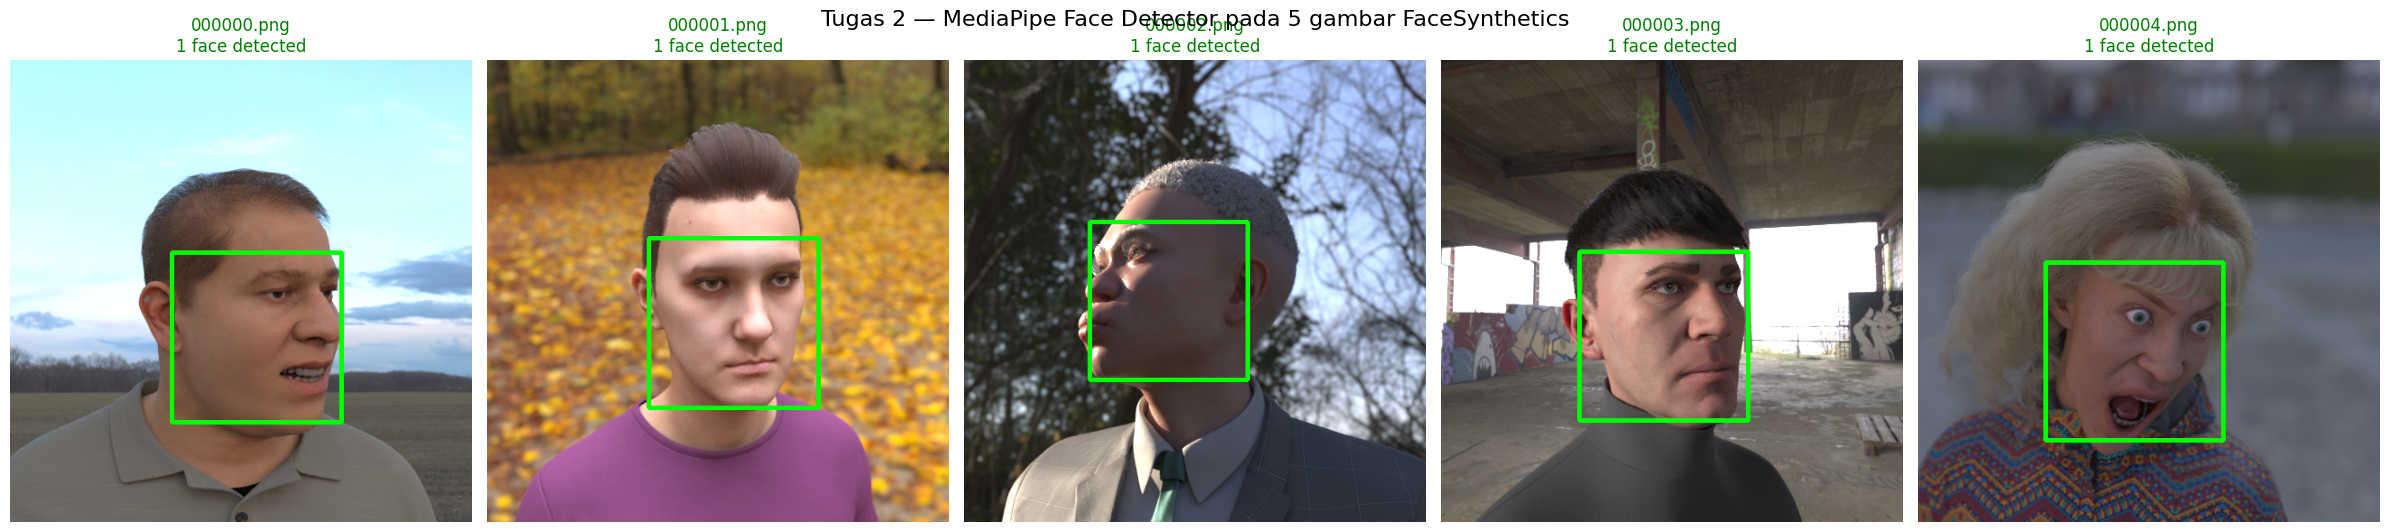

In [24]:
fig, axes = plt.subplots(1, 5, figsize=(24, 5.5))
for ax, (vis, name, caption) in zip(axes, face_vis):
    ax.imshow(vis)
    ax.set_title(f"{name}\n{caption}", fontsize=12,
                 color=("green" if not caption.startswith("0") else "red"))
    ax.axis("off")
fig.suptitle("Tugas 2 — MediaPipe Face Detector pada 5 gambar FaceSynthetics", fontsize=16)
plt.tight_layout()
plt.show()

## Step 2.6 — Ringkasan jumlah wajah dan analisis variasi hasil

In [25]:
counts = df_face["Jumlah wajah"].tolist()
print("Jumlah wajah per gambar:", dict(zip(df_face["File"], counts)))
print(f"Total wajah terdeteksi : {sum(counts)} pada {len(counts)} gambar")
print(f"Gambar tanpa deteksi   : {sum(c == 0 for c in counts)}")

def build_face_analysis(df):
    counts = df["Jumlah wajah"].tolist()
    zero = df[df["Jumlah wajah"] == 0]["File"].tolist()
    multi = df[df["Jumlah wajah"] > 1]["File"].tolist()
    s1 = f"Face Detector menemukan {sum(counts)} wajah pada {len(counts)} gambar (per gambar: {counts})."
    if zero:
        s2 = ("Tidak ada wajah pada " + ", ".join(zero) + ", kemungkinan karena sudut pandang ekstrem, "
              "occlusion, atau wajah terlalu kecil sehingga di bawah ambang keyakinan 0.5.")
    elif multi:
        s2 = ("Lebih dari satu kotak pada " + ", ".join(multi) + "; periksa visual apakah itu wajah nyata atau deteksi ganda.")
    else:
        s2 = ("Semua gambar menghasilkan deteksi, tetapi ukuran dan posisi kotak berbeda menurut sudut pandang kepala "
              "dan occlusion (rambut, kacamata, aksesori).")
    s3 = ("BlazeFace short-range dirancang untuk wajah dekat kamera sehingga wajah kecil atau menyamping paling rentan "
          "terlewat; ini hanya deteksi lokasi, bukan pengenalan identitas.")
    return " ".join([s1, s2, s3])

analysis_face = build_face_analysis(df_face)
display(Markdown("**Analisis Tugas 2 (draf 3 kalimat dari hasil):** " + analysis_face))

Jumlah wajah per gambar: {'000000.png': 1, '000001.png': 1, '000002.png': 1, '000003.png': 1, '000004.png': 1}
Total wajah terdeteksi : 5 pada 5 gambar
Gambar tanpa deteksi   : 0


**Analisis Tugas 2 (draf 3 kalimat dari hasil):** Face Detector menemukan 5 wajah pada 5 gambar (per gambar: [1, 1, 1, 1, 1]). Semua gambar menghasilkan deteksi, tetapi ukuran dan posisi kotak berbeda menurut sudut pandang kepala dan occlusion (rambut, kacamata, aksesori). BlazeFace short-range dirancang untuk wajah dekat kamera sehingga wajah kecil atau menyamping paling rentan terlewat; ini hanya deteksi lokasi, bukan pengenalan identitas.

**Catatan pengamatan pribadi (Tugas 2):**

Semua gambar berhasil dideteksi masing-masing 1 wajah, namun ketepatan kotak deteksi dan skor keyakinannya cukup terpengaruh oleh sudut pandang dan ekspresi wajah. Pada `000002.png`, posisi kepala yang menoleh tajam ke samping dengan pencahayaan latar cukup terang membuat skornya turun menjadi 0.84 dan sisi kiri kotak sedikit memotong bagian bibir subjek. Penurunan skor serupa juga terlihat pada `000004.png` (0.86) akibat posisi kepala yang menunduk dengan ekspresi mulut terbuka lebar, sedangkan pose yang lebih frontal seperti `000000.png` (0.94) dan `000001.png` (0.93) menghasilkan kotak yang jauh lebih presisi.

---
# Ringkasan, Visualisasi, dan Atribusi

## Step 3.1 — Pemeriksaan akhir

In [26]:
checks = {
    "Gestur: 10 gambar (5 palm + 5 fist)": len(df_gesture) == 10
        and (df_gesture["Label folder"] == "PALM").sum() == 5
        and (df_gesture["Label folder"] == "FIST").sum() == 5,
    "Gestur: 10 hasil visual berlabel ditampilkan": len(gesture_vis) == 10,
    "Gestur: jumlah prediksi benar dilaporkan": "n_correct" in globals(),
    "Wajah: 5 gambar utama (bukan *_seg.png)": len(df_face) == 5
        and not any("_seg" in f for f in df_face["File"]),
    "Wajah: 5 hasil visual + jumlah wajah per gambar": len(face_vis) == 5 and "Jumlah wajah" in df_face,
    "Analisis kedua tugas tersedia": bool(analysis_gesture) and bool(analysis_face),
}
for k, v in checks.items():
    print(("[OK]   " if v else "[GAGAL]"), k)
assert all(checks.values()), "Ada ketentuan yang belum terpenuhi, periksa kembali."

display(Markdown(f"""
**Rekap hasil**

- Tugas 1 (gestur): **{n_correct}/{n_total}** prediksi benar, {n_not_det} NOT DETECTED.
- Tugas 2 (wajah): **{sum(df_face['Jumlah wajah'])}** wajah terdeteksi pada **5** gambar ({df_face['Jumlah wajah'].tolist()}).
"""))

[OK]    Gestur: 10 gambar (5 palm + 5 fist)
[OK]    Gestur: 10 hasil visual berlabel ditampilkan
[OK]    Gestur: jumlah prediksi benar dilaporkan
[OK]    Wajah: 5 gambar utama (bukan *_seg.png)
[OK]    Wajah: 5 hasil visual + jumlah wajah per gambar
[OK]    Analisis kedua tugas tersedia



**Rekap hasil**

- Tugas 1 (gestur): **10/10** prediksi benar, 0 NOT DETECTED.
- Tugas 2 (wajah): **5** wajah terdeteksi pada **5** gambar ([1, 1, 1, 1, 1]).


## Step 3.2 — Sumber Data, Referensi, dan Dokumentasi Repositori

### 1. Repositori Dokumentasi Proyek (GitHub)
Kode sumber notebook, dokumentasi arsitektur *pipeline*, serta ringkasan evaluasi eksperimen untuk tugas ini juga didokumentasikan pada repositori GitHub berikut (tanpa menyertakan ulang berkas citra mentah sesuai ketentuan lisensi dataset):
* **GitHub Repository**: [https://github.com/nadhif-royal/mediapipe-hand-gesture-face-detection](https://github.com/nadhif-royal/mediapipe-hand-gesture-face-detection)

### 2. Tabel Dataset dan Sumber Model Pra-latih

| Dataset / Model | Peran pada Tugas | Sumber Resmi | Lisensi |
|---|---|---|---|
| **HaGRID** | 5 gambar `palm` + 5 gambar `fist` | <https://github.com/hukenovs/hagrid> · [Paper WACV 2024](https://openaccess.thecvf.com/content/WACV2024/html/Kapitanov_HaGRID_--_HAnd_Gesture_Recognition_Image_Dataset_WACV_2024_paper.html) | Lihat folder `license` di repositori (varian CC BY-SA 4.0); atribusi dan ketentuan berbagi berlaku |
| **Microsoft FaceSynthetics** | 5 gambar wajah utama dari sampel 100 gambar | <https://github.com/microsoft/FaceSynthetics> · [Sampel ZIP](https://facesyntheticspubwedata.z6.web.core.windows.net/iccv-2021/dataset_100.zip) · [Paper](https://microsoft.github.io/FaceSynthetics/) | [LICENSE.txt](https://github.com/microsoft/FaceSynthetics/blob/main/LICENSE.txt), riset nonkomersial |
| **MediaPipe Pre-trained Models** | `hand_landmarker.task` & `blaze_face_short_range.tflite` | [Hand Landmarker Docs](https://ai.google.dev/edge/mediapipe/solutions/vision/hand_landmarker/python) · [Face Detector Docs](https://ai.google.dev/edge/mediapipe/solutions/vision/face_detector/python) | Apache License 2.0 (Google MediaPipe) |

### 3. Daftar Pustaka

[1] Kapitanov, A., Kvanchiani, K., Nagaev, A., Kraynov, R., & Makhliarchuk, A. (2024). *HaGRID — HAnd Gesture Recognition Image Dataset*. Proceedings of the IEEE/CVF Winter Conference on Applications of Computer Vision (WACV), 4572–4581.

[2] Wood, E., Baltrušaitis, T., Hewitt, C., Dziadzio, S., Cashman, T. J., & Shotton, J. (2021). *Fake It Till You Make It: Face Analysis in the Wild Using Synthetic Data Alone*. Proceedings of the IEEE/CVF International Conference on Computer Vision (ICCV), 3681–3691. <https://microsoft.github.io/FaceSynthetics/>

[3] HaGRID authors. (n.d.). *HaGRID official repository and license*. <https://github.com/hukenovs/hagrid>

[4] Microsoft. (n.d.). *FaceSynthetics dataset and Research Use of Data Agreement*. <https://github.com/microsoft/FaceSynthetics>

#### Catatan Etika Penggunaan Data

Tugas ini hanya melakukan deteksi gestur tangan dan lokasi wajah pada dataset publik/sintetis. Tidak ada pengumpulan foto orang lain dan tidak ada identifikasi individu. Gambar dataset tidak didistribusikan ulang di dalam notebook maupun repositori GitHub ini.